--- Logistic Regression Classification Results ---

Classes: ['cel' 'cla' 'flu' 'gac' 'gel' 'org' 'pia' 'sax' 'tru' 'vio' 'voi']

---Logistic Regression Results---

Accuracy: 0.4646
Precision: 0.4674015824450696
Recall   : 0.4645786726323639
F1 Score : 0.4610698447422977

Classification Report:
              precision    recall  f1-score   support

         cel       0.64      0.41      0.50        95
         cla       0.49      0.45      0.47        96
         flu       0.45      0.41      0.43        85
         gac       0.49      0.44      0.46       151
         gel       0.41      0.43      0.42       139
         org       0.46      0.56      0.51       145
         pia       0.46      0.55      0.50       142
         sax       0.36      0.25      0.30       114
         tru       0.49      0.45      0.47       119
         vio       0.45      0.45      0.45       109
         voi       0.46      0.61      0.53       146

    accuracy                           0.46      1341


<Figure size 1000x800 with 0 Axes>

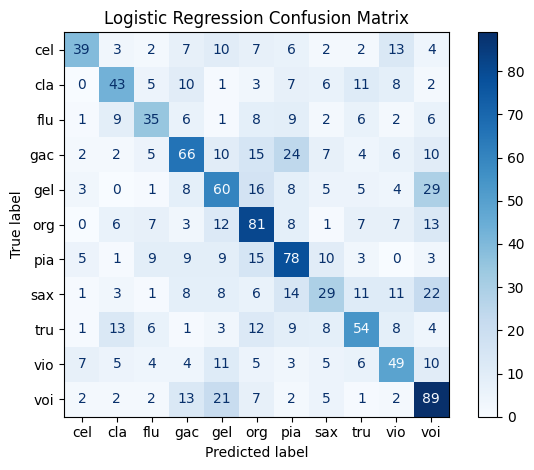

In [4]:
from sklearn.linear_model import LogisticRegression as logreg
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# 1. Load the dataset
data=pd.read_csv(r"C:\Users\LENOVO\Documents\ML Project(Instrument Classifier)\Music Dataset.csv")
X = data.drop("Instrument",axis=1)
y = data["Instrument"]

# 2. Split the data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Initialize the model
model=logreg(max_iter=200)
model.fit(X_train,y_train)

y_pred=model.predict(X_test)

# 4. Analyze
print(f"--- Logistic Regression Classification Results ---\n")
print("Classes:", model.classes_)

precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")
print(f"\n---Logistic Regression Results---\n")

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 5. Display confusion matrix
conf_mat = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=conf_mat, display_labels=model.classes_).plot(cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.tight_layout()
plt.show()